# FreshCrate Price-Framing A/B Test

**Business question:** Does showing the price as **"$9.99 / serving"** (treatment) instead of **"$79.92 / week"** (control) on the plan-selection page increase the share of visitors who place a first order — and is the difference real or noise?

| | |
|---|---|
| **Test window** | 14 days, Sep 14 – Sep 27, 2026 |
| **Unit of randomization** | Visitor reaching the plan-selection page |
| **Primary metric** | Conversion = visitor → first order placed (binary) |
| **Secondary metric** | Revenue per visitor (continuous, first box) |
| **Funnel** | visit → plan selected → checkout started → order placed |

**Contents**
1. Exploratory data analysis & data quality
2. Choosing the right hypothesis test
3. Statistical analysis — p-value, confidence interval, effect size, power
4. Novelty effect & segmentation
5. Conversion funnel

## 1. Exploratory Data Analysis

Before testing anything, we confirm three things: the data is clean, the randomization worked, and we understand the shape of each metric. A significant result on broken data is worse than no result.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: one fixed color per group everywhere in the project
COLORS = {"control": "#2a78d6", "treatment": "#eb6834"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5, "lines.linewidth": 2, "legend.frameon": False,
})

### 1.1 Load the raw data

In [2]:
raw = pd.read_csv(DATA_DIR / "ab_test_data.csv", parse_dates=["enrolled_at"])
raw["date"] = pd.to_datetime(raw["date"])
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Window: {raw['date'].min():%Y-%m-%d} to {raw['date'].max():%Y-%m-%d}")
raw.head()

Rows: 39,346   Columns: 12
Window: 2026-09-14 to 2026-09-27


,user_id,enrolled_at,date,day_of_test,group,device,user_type,plan_selected,checkout_started,order_placed,plan_name,revenue
0,u116888,2026-09-14 00:00:44,2026-09-14,0,control,mobile,returning,0,0,0,NaN,0.0000
1,u102453,2026-09-14 00:01:32,2026-09-14,0,treatment,desktop,new,1,0,0,NaN,0.0000
2,u130775,2026-09-14 00:01:46,2026-09-14,0,control,mobile,returning,0,0,0,NaN,0.0000
3,u137787,2026-09-14 00:01:47,2026-09-14,0,control,mobile,new,0,0,0,NaN,0.0000
4,u138382,2026-09-14 00:02:12,2026-09-14,0,control,mobile,new,0,0,0,NaN,0.0000


### 1.2 Data quality checks

Four checks every A/B dataset should pass: **duplicates** (one visitor counted twice inflates sample size), **missing values**, **funnel logic** (you can't place an order without starting checkout), and **metric consistency** (revenue > 0 exactly when an order exists).

In [3]:
stage_cols = ["plan_selected", "checkout_started", "order_placed"]

checks = {
    "Exact duplicate rows": raw.duplicated().sum(),
    "Duplicate user_ids": raw["user_id"].duplicated().sum(),
    "Missing device": raw["device"].isna().sum(),
    "Missing user_type": raw["user_type"].isna().sum(),
    "Checkout without plan selected": ((raw.checkout_started == 1) & (raw.plan_selected == 0)).sum(),
    "Order without checkout started": ((raw.order_placed == 1) & (raw.checkout_started == 0)).sum(),
    "Revenue > 0 without order": ((raw.revenue > 0) & (raw.order_placed == 0)).sum(),
    "Order with revenue = 0": ((raw.order_placed == 1) & (raw.revenue <= 0)).sum(),
    "Users seen in both groups": raw.groupby("user_id")["group"].nunique().gt(1).sum(),
}
quality = pd.DataFrame.from_dict(checks, orient="index", columns=["count"])
quality["status"] = np.where(quality["count"] == 0, "OK", "FIX")
quality

,count,status
Exact duplicate rows,118,FIX
Duplicate user_ids,118,FIX
Missing device,193,FIX
Missing user_type,0,OK
Checkout without plan selected,0,OK
Order without checkout started,31,FIX
Revenue > 0 without order,0,OK
Order with revenue = 0,0,OK
Users seen in both groups,0,OK


**Cleaning decisions** (each one written down so a reviewer can disagree with it):

- **Duplicate rows** are the same event logged twice → keep the first occurrence per `user_id`.
- **Missing device** (~0.5%) → keep the rows for the overall test, label `unknown`, and exclude them only from the device segmentation. Dropping them would throw away valid conversions.
- **Order without checkout** is a tracking bug: an order is proof that checkout happened → set `checkout_started = 1`. Dropping these rows would delete real buyers and bias conversion downward.
- No user appears in both groups, so there is no cross-contamination to handle.

In [4]:
df = raw.drop_duplicates(subset="user_id", keep="first").copy()
df["device"] = df["device"].fillna("unknown")
bug = (df.order_placed == 1) & (df.checkout_started == 0)
df.loc[bug, "checkout_started"] = 1

print(f"Removed duplicates:         {len(raw) - len(df):,}")
print(f"Repaired funnel rows:       {bug.sum():,}")
print(f"Clean rows:                 {len(df):,}")
assert not df["user_id"].duplicated().any()
assert ((df.order_placed <= df.checkout_started) & (df.checkout_started <= df.plan_selected)).all()

df.to_csv(DATA_DIR / "ab_test_clean.csv", index=False)

Removed duplicates:         118
Repaired funnel rows:       31
Clean rows:                 39,228


### 1.3 Sample Ratio Mismatch (SRM) check

We designed a 50/50 split, so the groups should be roughly equal in size. A chi-square goodness-of-fit test asks whether the observed split is plausible under 50/50. If p < 0.01, randomization or logging is broken and **no result from this test should be trusted** — this is the first check product teams at large tech companies run.

In [5]:
counts = df["group"].value_counts().reindex(["control", "treatment"])
expected = np.full(2, counts.sum() / 2)
chi2, p_srm = stats.chisquare(counts, f_exp=expected)

print(counts.to_string())
print(f"\nTreatment share: {counts['treatment'] / counts.sum():.2%}  (designed: 50.00%)")
print(f"SRM chi-square = {chi2:.3f},  p = {p_srm:.4f}")
print("PASS — split is consistent with 50/50" if p_srm >= 0.01 else "FAIL — investigate assignment before analyzing")

group
control      19752
treatment    19476

Treatment share: 49.65%  (designed: 50.00%)
SRM chi-square = 1.942,  p = 0.1635
PASS — split is consistent with 50/50


### 1.4 Randomization balance

If assignment is random, the mix of devices and new/returning users should be the same in both groups. A chi-square test of independence checks each attribute; a big imbalance would mean a segment, not the price framing, could explain the result.

In [6]:
rows = []
for col in ["device", "user_type"]:
    tab = pd.crosstab(df[col], df["group"])
    _, p, _, _ = stats.chi2_contingency(tab)
    share = pd.crosstab(df[col], df["group"], normalize="columns")
    for level in share.index:
        rows.append({"attribute": col, "level": level,
                     "control_share": share.loc[level, "control"],
                     "treatment_share": share.loc[level, "treatment"],
                     "balance_p_value": p})
balance = pd.DataFrame(rows)
balance

,attribute,level,control_share,treatment_share,balance_p_value
0,device,desktop,0.3752,0.3789,0.1879
1,device,mobile,0.6193,0.6168,0.1879
2,device,unknown,0.0055,0.0043,0.1879
3,user_type,new,0.7034,0.6959,0.1105
4,user_type,returning,0.2966,0.3041,0.1105


### 1.5 Funnel rates by group

Each stage shown two ways: **share of all visitors** reaching it, and **step rate** (share of the previous stage that continues). The step rates tell us *where* in the funnel the groups differ.

In [7]:
g = df.groupby("group")
counts_tbl = pd.DataFrame({
    "visitors": g.size(),
    "plan_selected": g["plan_selected"].sum(),
    "checkout_started": g["checkout_started"].sum(),
    "orders": g["order_placed"].sum(),
}).T
print(counts_tbl.to_string(), "\n")

rates = pd.DataFrame({
    "select_rate (visit→plan)": g["plan_selected"].mean(),
    "checkout_given_select": g["checkout_started"].sum() / g["plan_selected"].sum(),
    "order_given_checkout": g["order_placed"].sum() / g["checkout_started"].sum(),
    "conversion (visit→order)": g["order_placed"].mean(),
    "revenue_per_visitor ($)": g["revenue"].mean(),
}).T
rates["relative_lift"] = (rates["treatment"] / rates["control"] - 1).map("{:+.1%}".format)
rates

group             control  treatment
visitors            19752      19476
plan_selected        4335       5341
checkout_started     2329       2728
orders                961       1110 



group,control,treatment,relative_lift
select_rate (visit→plan),0.2195,0.2742,+25.0%
checkout_given_select,0.5373,0.5108,-4.9%
order_given_checkout,0.4126,0.4069,-1.4%
conversion (visit→order),0.0487,0.0570,+17.1%
revenue_per_visitor ($),4.2342,5.1389,+21.4%


### 1.6 Daily traffic and conversion

Daily volume should move together for both groups (same traffic, split randomly). Large gaps on a single day point to an assignment or logging outage.

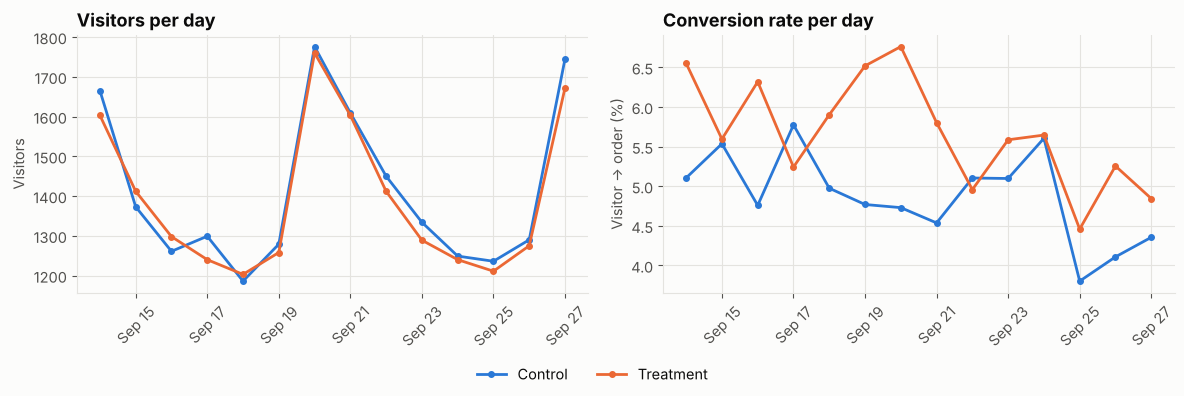

In [8]:
daily = (df.groupby(["date", "group"])
           .agg(visitors=("user_id", "size"), conversion=("order_placed", "mean"))
           .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for grp, d in daily.groupby("group"):
    axes[0].plot(d["date"], d["visitors"], color=COLORS[grp], marker="o", markersize=4, label=grp.title())
    axes[1].plot(d["date"], d["conversion"] * 100, color=COLORS[grp], marker="o", markersize=4, label=grp.title())
axes[0].set_title("Visitors per day")
axes[0].set_ylabel("Visitors")
axes[1].set_title("Conversion rate per day")
axes[1].set_ylabel("Visitor → order (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG_DIR / "01_daily_traffic_conversion.png", dpi=150)
plt.show()

### 1.7 Shape of each metric

The metric's *shape* decides which statistical test is valid (Section 2). Conversion is 0/1 per visitor. Revenue per visitor is almost all zeros with a long right tail among buyers — far from a bell curve.

Share of visitors with $0 revenue:
group
control      95.1%
treatment    94.3% 

Revenue among buyers:
               count    mean     50%     min      max
group                                                
control     961.0000 87.0300 75.7200 46.9500 154.8300
treatment 1,110.0000 90.1700 90.9100 46.9500 154.8300 

Skewness of revenue per visitor (all visitors): 4.69  (0 = symmetric)


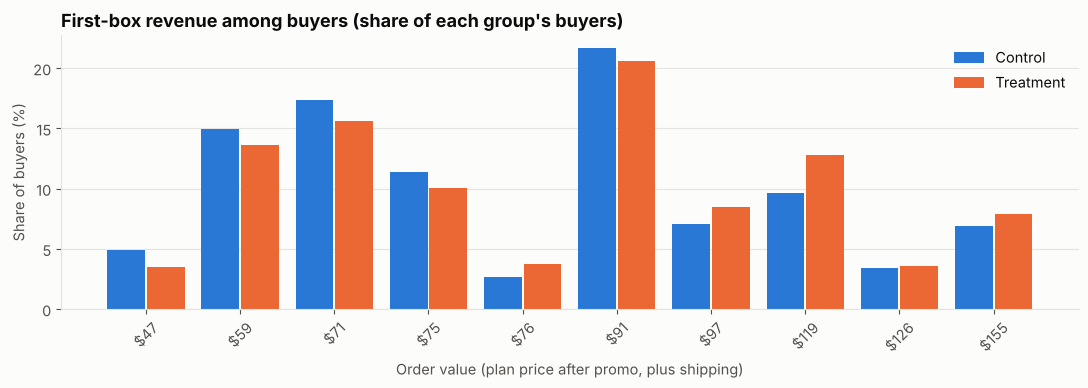

In [9]:
zero_share = df.groupby("group")["revenue"].apply(lambda s: (s == 0).mean())
print("Share of visitors with $0 revenue:")
print(zero_share.map("{:.1%}".format).to_string(), "\n")

buyers = df[df.order_placed == 1]
print("Revenue among buyers:")
print(buyers.groupby("group")["revenue"].describe()[["count", "mean", "50%", "min", "max"]].round(2).to_string(), "\n")
print(f"Skewness of revenue per visitor (all visitors): {stats.skew(df['revenue']):.2f}  (0 = symmetric)")

# Revenue takes a handful of discrete values (plan price x promo code), so compare
# each group's share of buyers at each price point rather than raw counts.
mix = (buyers.groupby("group")["revenue"].value_counts(normalize=True)
             .unstack("group").fillna(0).sort_index())
x = np.arange(len(mix))
w = 0.4
fig, ax = plt.subplots(figsize=(11, 4))
for i, grp in enumerate(["control", "treatment"]):
    ax.bar(x + (i - 0.5) * (w + 0.02), mix[grp] * 100, width=w, color=COLORS[grp], label=grp.title())
ax.set_xticks(x, [f"${v:,.0f}" for v in mix.index], rotation=45)
ax.set_title("First-box revenue among buyers (share of each group's buyers)")
ax.set_xlabel("Order value (plan price after promo, plus shipping)")
ax.set_ylabel("Share of buyers (%)")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_buyer_revenue_distribution.png", dpi=150)
plt.show()

### EDA takeaways

- Data issues found and fixed: duplicate events, missing device, and orders missing their checkout event.
- The 50/50 split holds (SRM passes) and device / user-type mix is balanced, so the groups are comparable.
- Treatment shows **more plan selections but a lower checkout step rate** — an early sign of a funnel tradeoff.
- Treatment buyers lean toward higher-value boxes ($97+), consistent with the cheaper per-serving price of 4-person plans.
- Conversion is binary; revenue per visitor is ~95% zeros and heavily skewed. These two shapes need **different tests**, which is the next section.

## 2. Choosing the Right Hypothesis Test

The test is decided by **what kind of number the metric is**, not by habit. Three questions, in order:

**Q1. Is the metric binary (0/1 per user)?** → **Two-proportion z-test**
- Conversion is "ordered or didn't". Each group's rate is a proportion, and with large samples the difference between two proportions is approximately normal.
- The **chi-square test of independence** on the 2×2 table (group × converted) is the *same test*: χ² = z², identical p-value. Use the z-test form because it also gives a signed difference and a confidence interval.
- If any cell has fewer than ~10 successes or failures, the normal approximation breaks → use **Fisher's exact test**.

**Q2. If continuous — is the sample large enough for the mean to behave normally?** → **Welch's t-test**
- The t-test does *not* need the raw data to be normal. It needs the **sample mean** to be roughly normal, which the Central Limit Theorem gives us once n is large enough.
- How large? Cochran's rule of thumb: **n > 25 × skewness²**. Heavier skew needs more data.
- Use **Welch's** version (not Student's) because it doesn't assume the two groups have equal variance. There's no downside with large samples, so it's the safe default.

**Q3. If the sample is too small for the skew, or the data is ordinal (ratings)?** → **Mann-Whitney U**
- It compares **ranks**, so outliers and skew can't dominate it.
- The catch: it tests whether one group tends to produce larger values. It does **not** test whether the *means* differ. Revenue decisions are about means (total revenue = mean × visitors), so Mann-Whitney is a fallback or robustness check here, not the primary test.
- With revenue, ~95% of values are tied at $0, which weakens the rank comparison even further.

The function below encodes this logic so the decision is explicit and reusable.

In [10]:
def select_test(a: pd.Series, b: pd.Series, min_cell: int = 10) -> dict:
    """Pick the right two-sample test for a metric and explain why."""
    a, b = a.dropna(), b.dropna()
    n_min = min(len(a), len(b))
    values = set(pd.unique(pd.concat([a, b])))

    if values <= {0, 1}:
        cells = [a.sum(), len(a) - a.sum(), b.sum(), len(b) - b.sum()]
        if min(cells) < min_cell:
            return {"metric_type": "binary", "test": "Fisher's exact test",
                    "reason": f"binary metric, smallest 2x2 cell = {min(cells)} < {min_cell}"}
        return {"metric_type": "binary", "test": "Two-proportion z-test",
                "reason": f"binary metric, smallest 2x2 cell = {min(cells):,} >= {min_cell}"}

    skew = max(abs(stats.skew(a)), abs(stats.skew(b)))
    n_needed = int(np.ceil(25 * skew ** 2))
    if n_min > n_needed:
        return {"metric_type": "continuous", "test": "Welch's t-test",
                "reason": f"skew {skew:.2f} needs n > {n_needed:,} for a normal mean; have n = {n_min:,}"}
    return {"metric_type": "continuous", "test": "Mann-Whitney U",
            "reason": f"skew {skew:.2f} needs n > {n_needed:,}; only n = {n_min:,}"}


ctrl, trt = df[df.group == "control"], df[df.group == "treatment"]
decisions = pd.DataFrame({
    "conversion": select_test(ctrl["order_placed"], trt["order_placed"]),
    "revenue_per_visitor": select_test(ctrl["revenue"], trt["revenue"]),
}).T
decisions

,metric_type,test,reason
conversion,binary,Two-proportion z-test,"binary metric, smallest 2x2 cell = 961 >= 10"
revenue_per_visitor,continuous,Welch's t-test,"skew 4.92 needs n > 606 for a normal mean; have n = 19,476"


### 2.1 Checking the logic on edge cases

A decision function is only trustworthy if it flips when it should. We feed it a tiny binary sample and a small, skewed continuous sample — it should choose Fisher's exact and Mann-Whitney.

In [11]:
rng = np.random.default_rng(0)
edge_cases = {
    "tiny binary (n=40)": (pd.Series(rng.binomial(1, 0.05, 40)), pd.Series(rng.binomial(1, 0.08, 40))),
    "small skewed revenue (n=200)": (ctrl["revenue"].sample(200, random_state=1),
                                     trt["revenue"].sample(200, random_state=1)),
    "symmetric continuous (n=200)": (pd.Series(rng.normal(30, 5, 200)), pd.Series(rng.normal(31, 5, 200))),
}
pd.DataFrame({k: select_test(*v) for k, v in edge_cases.items()}).T

,metric_type,test,reason
tiny binary (n=40),binary,Fisher's exact test,"binary metric, smallest 2x2 cell = 2 < 10"
small skewed revenue (n=200),continuous,Mann-Whitney U,skew 6.24 needs n > 973; only n = 200
symmetric continuous (n=200),continuous,Welch's t-test,skew 0.35 needs n > 4 for a normal mean; have n = 200


### 2.2 Proof 1: the chi-square test and the z-test are the same test

Same data, two formulas: the z statistic squared equals the chi-square statistic.

In [12]:
from statsmodels.stats.proportion import proportions_ztest

successes = np.array([trt["order_placed"].sum(), ctrl["order_placed"].sum()])
totals = np.array([len(trt), len(ctrl)])
z, _ = proportions_ztest(successes, totals)

table = pd.crosstab(df["group"], df["order_placed"])
chi2_stat, _, _, _ = stats.chi2_contingency(table, correction=False)

print(table, "\n")
print(f"z        = {z:.4f}")
print(f"z²       = {z**2:.4f}")
print(f"chi²     = {chi2_stat:.4f}   (no continuity correction)")

order_placed      0     1
group                    
control       18791   961
treatment     18366  1110 

z        = 3.6932
z²       = 13.6399
chi²     = 13.6399   (no continuity correction)


### 2.3 Proof 2: why a t-test is valid on skewed revenue

The left panel is the raw revenue per visitor: a spike at $0 and a long tail. The right panel resamples the control group 5,000 times (bootstrap) and plots the **mean** of each resample. The means form a bell curve. The t-test only relies on that right-hand shape, which is why sample size, not the raw shape, decides between t-test and Mann-Whitney.

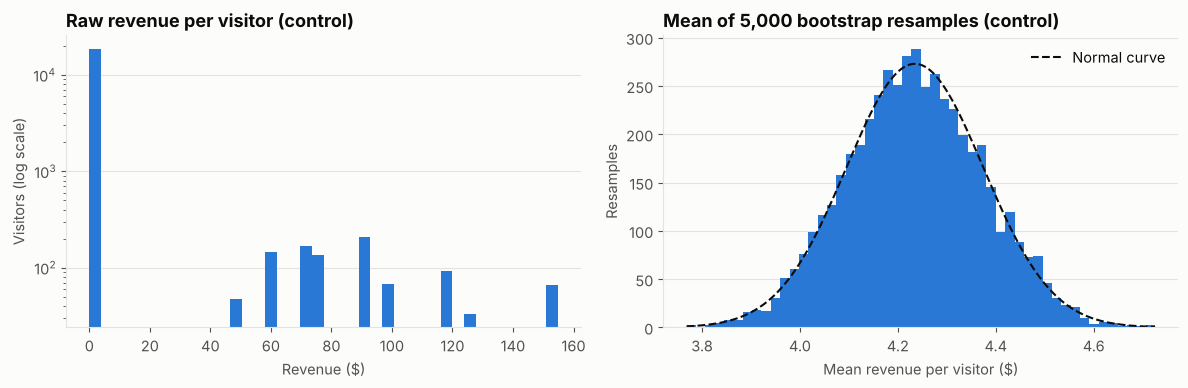

Skewness of raw revenue:       4.92
Skewness of bootstrap means:   0.03   (≈ 0 means symmetric, bell-shaped)


In [13]:
boot_rng = np.random.default_rng(42)
rev_c = ctrl["revenue"].to_numpy()
boot_means = np.array([boot_rng.choice(rev_c, size=len(rev_c), replace=True).mean() for _ in range(5000)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rev_c, bins=40, color=COLORS["control"])
axes[0].set_yscale("log")
axes[0].set_title("Raw revenue per visitor (control)")
axes[0].set_xlabel("Revenue ($)")
axes[0].set_ylabel("Visitors (log scale)")

_, edges, _ = axes[1].hist(boot_means, bins=50, color=COLORS["control"])
xs = np.linspace(edges[0], edges[-1], 200)
pdf = stats.norm.pdf(xs, boot_means.mean(), boot_means.std())
axes[1].plot(xs, pdf * len(boot_means) * (edges[1] - edges[0]), color=INK, linewidth=1.5,
             linestyle="--", label="Normal curve")
axes[1].set_title("Mean of 5,000 bootstrap resamples (control)")
axes[1].set_xlabel("Mean revenue per visitor ($)")
axes[1].set_ylabel("Resamples")
axes[1].legend()
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_clt_revenue.png", dpi=150)
plt.show()

print(f"Skewness of raw revenue:       {stats.skew(rev_c):.2f}")
print(f"Skewness of bootstrap means:   {stats.skew(boot_means):.2f}   (≈ 0 means symmetric, bell-shaped)")

### Test selection — decision

| Metric | Type | Primary test | Robustness check |
|---|---|---|---|
| Conversion (visit → order) | Binary | Two-proportion z-test (≡ chi-square) | — |
| Revenue per visitor | Continuous, skewed, large n | Welch's t-test | Mann-Whitney U + bootstrap CI |

Both tests are **two-tailed**: we test for a difference in *either* direction, because a price change can hurt as easily as help, and deciding the direction in advance would hide a harmful result.

## 3. Statistical Analysis

### 3.1 Hypotheses (written before looking at p-values)

**Primary metric: conversion rate** (visitor → first order), *p* = true conversion rate

- **H₀ (null):** *p*<sub>treatment</sub> = *p*<sub>control</sub> — the price framing has no effect on conversion.
- **H₁ (alternative):** *p*<sub>treatment</sub> ≠ *p*<sub>control</sub> — the framing changes conversion, in either direction.

**Secondary metric: revenue per visitor**, *μ* = true mean revenue per visitor

- **H₀:** *μ*<sub>treatment</sub> = *μ*<sub>control</sub>  **H₁:** *μ*<sub>treatment</sub> ≠ *μ*<sub>control</sub>

**Decision rule:** significance level **α = 0.05**, two-tailed. Reject H₀ if p < 0.05.

**Pre-registered minimum detectable effect (MDE):** before launch, the team agreed a **10% relative lift** in conversion is the smallest change worth shipping (it covers the design and engineering cost). Power is judged against this number.

In [14]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower, TTestIndPower

ALPHA = 0.05
MDE_RELATIVE = 0.10

n_c, n_t = len(ctrl), len(trt)
x_c, x_t = ctrl["order_placed"].sum(), trt["order_placed"].sum()
p_c, p_t = x_c / n_c, x_t / n_t
print(f"Control:   {x_c:,} / {n_c:,} = {p_c:.4%}")
print(f"Treatment: {x_t:,} / {n_t:,} = {p_t:.4%}")
print(f"Absolute difference: {p_t - p_c:+.4%} points    Relative lift: {p_t / p_c - 1:+.2%}")

Control:   961 / 19,752 = 4.8653%
Treatment: 1,110 / 19,476 = 5.6993%
Absolute difference: +0.8340% points    Relative lift: +17.14%


### 3.2 Conversion: p-value

**What the p-value means:** *if* the price framing truly had zero effect, the p-value is the probability of seeing a difference at least this large just from random assignment. A small p-value means "chance alone is a poor explanation." It is **not** the probability that the treatment works, and it says nothing about how *big* the effect is.

In [15]:
z_stat, p_value_conv = proportions_ztest([x_t, x_c], [n_t, n_c], alternative="two-sided")
print(f"z = {z_stat:.3f}")
print(f"p-value = {p_value_conv:.5f}")
print("Decision:", "Reject H0 — the difference is unlikely to be chance" if p_value_conv < ALPHA
      else "Fail to reject H0 — the difference is consistent with chance")

z = 3.693
p-value = 0.00022
Decision: Reject H0 — the difference is unlikely to be chance


### 3.3 Conversion: 95% confidence interval for the difference

The confidence interval gives the **range of plausible true effects**. It is more useful than the p-value because it shows size *and* uncertainty at once. If the interval excludes 0, the result is significant at α = 0.05 — the two always agree.

In [16]:
ci_low, ci_high = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="wald", compare="diff", alpha=ALPHA)
ci_rel_low, ci_rel_high = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="log", compare="ratio", alpha=ALPHA)

print(f"Difference in conversion: {p_t - p_c:+.3%} points")
print(f"95% CI (absolute):        [{ci_low:+.3%}, {ci_high:+.3%}] points")
print(f"95% CI (relative lift):   [{ci_rel_low - 1:+.1%}, {ci_rel_high - 1:+.1%}]")
print(f"\nPer 1,000 visitors: {1000 * (p_t - p_c):+.1f} extra orders "
      f"(95% CI {1000 * ci_low:+.1f} to {1000 * ci_high:+.1f})")

Difference in conversion: +0.834% points
95% CI (absolute):        [+0.391%, +1.277%] points
95% CI (relative lift):   [+7.7%, +27.4%]

Per 1,000 visitors: +8.3 extra orders (95% CI +3.9 to +12.8)


### 3.4 Effect size: Cohen's h (proportions) and Cohen's d (means)

**Why effect size matters more than the p-value alone:** with a big enough sample, a meaninglessly tiny difference becomes "significant." Effect size measures *how big* the difference is, independent of sample size, so it answers "does this matter?" rather than "is this real?"

- **Cohen's h** — for two **proportions**: h = 2·arcsin(√p₁) − 2·arcsin(√p₂). The arcsine transform puts differences on an equal footing whether rates are near 5% or near 50%.
- **Cohen's d** — for two **means**: d = (mean₁ − mean₂) / pooled standard deviation, i.e. the difference in units of "typical spread."
- Textbook benchmarks (0.2 small, 0.5 medium, 0.8 large) come from psychology. In A/B testing almost every real effect is "small" by that scale, so judge it against the business MDE instead.

In [17]:
cohens_h = proportion_effectsize(p_t, p_c)          # 2*asin(sqrt(p_t)) - 2*asin(sqrt(p_c))
mde_p_t = p_c * (1 + MDE_RELATIVE)
mde_h = proportion_effectsize(mde_p_t, p_c)

print(f"Cohen's h (observed):            {cohens_h:.4f}")
print(f"Cohen's h of the 10% MDE:        {mde_h:.4f}")
print(f"Observed effect vs MDE:          {cohens_h / mde_h:.2f}x the smallest effect worth shipping")

Cohen's h (observed):            0.0373
Cohen's h of the 10% MDE:        0.0221
Observed effect vs MDE:          1.69x the smallest effect worth shipping


### 3.5 Revenue per visitor: Welch's t-test, CI, Cohen's d, and robustness checks

In [18]:
rev_c, rev_t = ctrl["revenue"].to_numpy(), trt["revenue"].to_numpy()
diff_rev = rev_t.mean() - rev_c.mean()

t_stat, p_value_rev = stats.ttest_ind(rev_t, rev_c, equal_var=False)

# Welch CI for the difference in means
v_t, v_c = rev_t.var(ddof=1) / len(rev_t), rev_c.var(ddof=1) / len(rev_c)
se = np.sqrt(v_t + v_c)
df_welch = (v_t + v_c) ** 2 / (v_t ** 2 / (len(rev_t) - 1) + v_c ** 2 / (len(rev_c) - 1))
t_crit = stats.t.ppf(1 - ALPHA / 2, df_welch)
rev_ci = (diff_rev - t_crit * se, diff_rev + t_crit * se)

# Cohen's d with pooled SD
pooled_sd = np.sqrt(((len(rev_t) - 1) * rev_t.var(ddof=1) + (len(rev_c) - 1) * rev_c.var(ddof=1))
                    / (len(rev_t) + len(rev_c) - 2))
cohens_d = diff_rev / pooled_sd

# Robustness 1: Mann-Whitney U (rank-based)
_, p_mwu = stats.mannwhitneyu(rev_t, rev_c, alternative="two-sided")

# Robustness 2: bootstrap CI for the difference in means (no distribution assumptions)
boot_rng = np.random.default_rng(7)
boot_diffs = np.array([
    boot_rng.choice(rev_t, len(rev_t)).mean() - boot_rng.choice(rev_c, len(rev_c)).mean()
    for _ in range(5000)
])
boot_ci = np.percentile(boot_diffs, [2.5, 97.5])

print(f"Revenue per visitor: control ${rev_c.mean():.3f}, treatment ${rev_t.mean():.3f}")
print(f"Difference: ${diff_rev:+.3f} per visitor  ({rev_t.mean() / rev_c.mean() - 1:+.1%})\n")
print(f"Welch's t-test:     t = {t_stat:.3f}, df = {df_welch:,.0f}, p = {p_value_rev:.5f}")
print(f"Welch 95% CI:       [${rev_ci[0]:+.3f}, ${rev_ci[1]:+.3f}] per visitor")
print(f"Bootstrap 95% CI:   [${boot_ci[0]:+.3f}, ${boot_ci[1]:+.3f}] per visitor   <- should match Welch")
print(f"Mann-Whitney U:     p = {p_mwu:.5f}                         <- should agree on direction")
print(f"Cohen's d:          {cohens_d:.4f}")
print(f"\nPer 1,000 visitors: ${1000 * diff_rev:+,.0f} revenue "
      f"(95% CI ${1000 * rev_ci[0]:+,.0f} to ${1000 * rev_ci[1]:+,.0f})")

Revenue per visitor: control $4.234, treatment $5.139
Difference: $+0.905 per visitor  (+21.4%)

Welch's t-test:     t = 4.300, df = 38,641, p = 0.00002
Welch 95% CI:       [$+0.492, $+1.317] per visitor
Bootstrap 95% CI:   [$+0.494, $+1.312] per visitor   <- should match Welch
Mann-Whitney U:     p = 0.00016                         <- should agree on direction
Cohen's d:          0.0435

Per 1,000 visitors: $+905 revenue (95% CI $+492 to $+1,317)


### 3.6 Power analysis: did we have enough data?

**Power** is the probability that a test detects an effect *when the effect is real*. 80% power means that if the true lift equals the MDE, 4 out of 5 runs of this experiment would come out significant and 1 would miss it. Power depends on three dials: sample size, effect size, and α.

**A trap to avoid:** "observed power" (power calculated from the effect you just measured) is just a re-expression of the p-value — a significant result always has high observed power. The meaningful question is: **did we have enough data to detect the pre-registered MDE?** We report both so the difference is visible.

In [19]:
power_calc = NormalIndPower()
ratio = n_t / n_c

power_at_mde = power_calc.power(effect_size=mde_h, nobs1=n_c, alpha=ALPHA, ratio=ratio)
power_observed = power_calc.power(effect_size=cohens_h, nobs1=n_c, alpha=ALPHA, ratio=ratio)
mde_detectable_h = power_calc.solve_power(nobs1=n_c, alpha=ALPHA, power=0.80, ratio=ratio)

# Convert the detectable h back into a conversion rate
p_detectable = np.sin(np.arcsin(np.sqrt(p_c)) + mde_detectable_h / 2) ** 2

print(f"Power to detect the 10% MDE with our sample:      {power_at_mde:.1%}")
print(f"'Observed power' at the measured effect:           {power_observed:.1%}  (not a meaningful check — see above)")
print(f"Smallest lift we could reliably detect (80% power): {p_detectable / p_c - 1:+.1%} relative")

Power to detect the 10% MDE with our sample:      59.1%
'Observed power' at the measured effect:           95.9%  (not a meaningful check — see above)
Smallest lift we could reliably detect (80% power): +12.9% relative


### 3.7 Sample size: how many users would we need for 80% power?

In [20]:
n_for_mde = power_calc.solve_power(effect_size=mde_h, alpha=ALPHA, power=0.80, ratio=1.0)
n_for_observed = power_calc.solve_power(effect_size=cohens_h, alpha=ALPHA, power=0.80, ratio=1.0)
daily_per_group = n_c / df["day_of_test"].nunique()

sample_table = pd.DataFrame({
    "target_lift": [f"{MDE_RELATIVE:.0%} (pre-registered MDE)", f"{p_t / p_c - 1:.1%} (observed)"],
    "users_per_group": [int(np.ceil(n_for_mde)), int(np.ceil(n_for_observed))],
    "days_at_current_traffic": [int(np.ceil(n_for_mde / daily_per_group)), int(np.ceil(n_for_observed / daily_per_group))],
    "we_had_per_group": [n_c, n_c],
})
sample_table["enough?"] = np.where(sample_table["we_had_per_group"] >= sample_table["users_per_group"], "Yes", "No")
sample_table

,target_lift,users_per_group,days_at_current_traffic,we_had_per_group,enough?
0,10% (pre-registered MDE),32130,23,19752,No
1,17.1% (observed),11275,8,19752,Yes


### 3.8 Power curves: what an underpowered test looks like

Each line shows how power grows with sample size for a given true lift. Our actual sample is the vertical line. Smaller effects need dramatically more data — sample size scales with **1 / effect²**, so halving the effect you want to detect roughly **quadruples** the users you need.

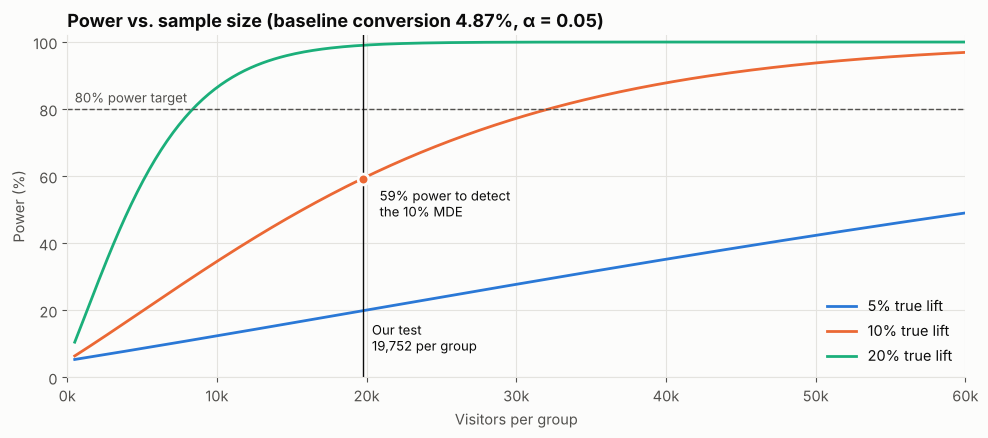

In [21]:
n_grid = np.linspace(500, 60000, 300)
lifts = [0.05, 0.10, 0.20]
lift_colors = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for lift, color in zip(lifts, lift_colors):
    h = proportion_effectsize(p_c * (1 + lift), p_c)
    pw = power_calc.power(effect_size=h, nobs1=n_grid, alpha=ALPHA, ratio=1.0)
    ax.plot(n_grid, pw * 100, color=color, label=f"{lift:.0%} true lift")
ax.axhline(80, color=INK_2, linewidth=1, linestyle="--")
ax.text(n_grid[0], 82, "80% power target", color=INK_2, fontsize=9.5)
ax.axvline(n_c, color=INK, linewidth=1)
ax.text(n_c + 600, 8, f"Our test\n{n_c:,} per group", color=INK, fontsize=9.5)
ax.scatter([n_c], [power_at_mde * 100], s=60, color=lift_colors[1], edgecolor=SURFACE, linewidth=2, zorder=5)
ax.annotate(f"{power_at_mde:.0%} power to detect\nthe 10% MDE", xy=(n_c, power_at_mde * 100), xytext=(12, -6),
            textcoords="offset points", va="top", color=INK, fontsize=9.5)
ax.set_xlim(0, n_grid[-1])
ax.set_ylim(0, 102)
ax.set_title("Power vs. sample size (baseline conversion 4.87%, α = 0.05)")
ax.set_xlabel("Visitors per group")
ax.set_ylabel("Power (%)")
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
fig.tight_layout()
fig.savefig(FIG_DIR / "04_power_curves.png", dpi=150)
plt.show()

### 3.9 Why underpowered tests are dangerous: the winner's curse

Low power doesn't just mean "might miss the effect." When an underpowered test *does* come out significant, the measured effect is usually **exaggerated**, because only the lucky high draws cross the significance line. We simulate 2,000 experiments with a true 10% lift at two sample sizes and compare.

In [22]:
sim_rng = np.random.default_rng(11)
true_pt = p_c * (1 + MDE_RELATIVE)

rows = []
for n in [3000, n_c]:
    xc = sim_rng.binomial(n, p_c, size=2000)
    xt = sim_rng.binomial(n, true_pt, size=2000)
    pc_hat, pt_hat = xc / n, xt / n
    pooled = (xc + xt) / (2 * n)
    z = (pt_hat - pc_hat) / np.sqrt(pooled * (1 - pooled) * 2 / n)
    sig = np.abs(z) > stats.norm.ppf(1 - ALPHA / 2)
    measured_lift = pt_hat / pc_hat - 1
    rows.append({
        "users_per_group": n,
        "share_significant (≈ power)": sig.mean(),
        "true_lift": MDE_RELATIVE,
        "avg_measured_lift_when_significant": measured_lift[sig & (z > 0)].mean(),
    })
winners_curse = pd.DataFrame(rows)
winners_curse["exaggeration"] = winners_curse["avg_measured_lift_when_significant"] / MDE_RELATIVE
winners_curse

,users_per_group,share_significant (≈ power),true_lift,avg_measured_lift_when_significant,exaggeration
0,3000,0.1400,0.1000,0.3213,3.2131
1,19752,0.6005,0.1000,0.1305,1.3050


### 3.10 Results summary

In [23]:
def usd(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):.2f}"

results = pd.DataFrame([
    {"metric": "Conversion rate", "test": "Two-proportion z-test",
     "control": f"{p_c:.2%}", "treatment": f"{p_t:.2%}",
     "difference": f"{p_t - p_c:+.2%} pts", "relative_lift": f"{p_t / p_c - 1:+.1%}",
     "95% CI": f"[{ci_low:+.2%}, {ci_high:+.2%}]", "p_value": f"{p_value_conv:.5f}",
     "effect_size": f"h = {cohens_h:.3f}", "power_at_MDE": f"{power_at_mde:.0%}"},
    {"metric": "Revenue / visitor", "test": "Welch's t-test",
     "control": f"${rev_c.mean():.2f}", "treatment": f"${rev_t.mean():.2f}",
     "difference": usd(diff_rev), "relative_lift": f"{rev_t.mean() / rev_c.mean() - 1:+.1%}",
     "95% CI": f"[{usd(rev_ci[0])}, {usd(rev_ci[1])}]", "p_value": f"{p_value_rev:.5f}",
     "effect_size": f"d = {cohens_d:.3f}", "power_at_MDE": "—"},
]).set_index("metric")
results

,test,control,treatment,difference,relative_lift,95% CI,p_value,effect_size,power_at_MDE
metric,,,,,,,,,
Conversion rate,Two-proportion z-test,4.87%,5.70%,+0.83% pts,+17.1%,"[+0.39%, +1.28%]",0.00022,h = 0.037,59%
Revenue / visitor,Welch's t-test,$4.23,$5.14,+$0.90,+21.4%,"[+$0.49, +$1.32]",0.00002,d = 0.043,—


### What the analysis says — and what it warns about

1. **The effect is real.** Conversion rose from 4.87% to 5.70% (p = 0.0002), and revenue per visitor rose by about $0.90 (p = 0.00002). Three different methods (Welch, bootstrap, Mann-Whitney) agree on revenue.
2. **But the test was underpowered for its own goal.** With ~19.7k users per group it had only **59% power** to detect the pre-registered 10% lift. It needed ~32k per group (~23 days at current traffic).
3. **So the 17% lift is probably an overestimate.** The winner's-curse simulation shows that when a test with this power comes out significant, the measured lift averages ~1.3x the true lift. The CI's lower bound (+7.7%) sits *below* the 10% MDE, so we cannot rule out an effect too small to justify the change.
4. **Bottom line so far:** the treatment almost certainly helps, but the *size* of the win is uncertain. The novelty check in the next section tells us whether the lift is shrinking over time, which would make this worse.

## 4. Novelty Effect & Segmentation

### 4.1 Novelty effect: is the lift fading?

A **novelty effect** is when users react to a change simply because it's *new*: they notice it, click on it, try it. The lift is largest in the first days and decays as returning traffic gets used to it. If we average over the whole test, a decaying lift makes the change look better than it will be in month three.

We check it three ways: the daily lift plotted over time, week 1 vs. week 2, and a regression that tests whether the lift changes by day.

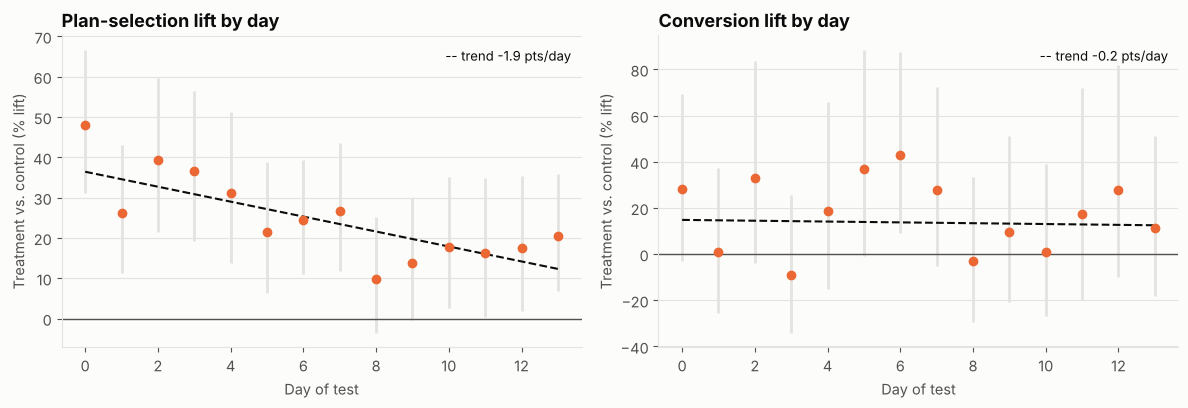

In [24]:
import statsmodels.formula.api as smf

df["treatment"] = (df["group"] == "treatment").astype(int)

def lift_ci(sub, metric):
    """Relative lift of treatment over control with a 95% CI (log-ratio method)."""
    c, t = sub[sub.treatment == 0][metric], sub[sub.treatment == 1][metric]
    xc, nc, xt, nt = c.sum(), len(c), t.sum(), len(t)
    lo, hi = confint_proportions_2indep(xt, nt, xc, nc, method="log", compare="ratio", alpha=ALPHA)
    return {"control_rate": xc / nc, "treatment_rate": xt / nt,
            "lift": (xt / nt) / (xc / nc) - 1, "ci_low": lo - 1, "ci_high": hi - 1,
            "n_control": nc, "n_treatment": nt}

daily_lift = {m: pd.DataFrame({d: lift_ci(sub, m) for d, sub in df.groupby("day_of_test")}).T
              for m in ["plan_selected", "order_placed"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
titles = {"plan_selected": "Plan-selection lift by day", "order_placed": "Conversion lift by day"}
for ax, (metric, d) in zip(axes, daily_lift.items()):
    days = d.index.to_numpy()
    ax.errorbar(days, d["lift"] * 100,
                yerr=[(d["lift"] - d["ci_low"]) * 100, (d["ci_high"] - d["lift"]) * 100],
                fmt="o", color=COLORS["treatment"], ecolor=GRID, elinewidth=2, capsize=0, markersize=6)
    # Trend line weighted by the inverse width of each day's CI
    w = 1 / ((d["ci_high"] - d["ci_low"]) ** 2)
    slope, intercept = np.polyfit(days, d["lift"] * 100, 1, w=np.sqrt(w))
    ax.plot(days, intercept + slope * days, color=INK, linewidth=1.5, linestyle="--")
    ax.text(0.98, 0.96, f"-- trend {slope:+.1f} pts/day", transform=ax.transAxes,
            ha="right", va="top", color=INK, fontsize=9.5)
    ax.axhline(0, color=INK_2, linewidth=1)
    ax.set_title(titles[metric])
    ax.set_xlabel("Day of test")
    ax.set_ylabel("Treatment vs. control (% lift)")
    ax.set_xticks(range(0, 14, 2))
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_novelty_effect.png", dpi=150)
plt.show()

Daily points have very wide intervals (~1,400 users per group per day), so no single day proves anything. Pooling days into weeks and fitting a regression across all users gives a much sharper answer.

In [25]:
df["week"] = np.where(df["day_of_test"] < 7, "Week 1 (days 0-6)", "Week 2 (days 7-13)")

week_rows = []
for metric in ["plan_selected", "order_placed"]:
    for wk, sub in df.groupby("week"):
        r = lift_ci(sub, metric)
        c, t = sub[sub.treatment == 0][metric], sub[sub.treatment == 1][metric]
        _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
        week_rows.append({"metric": metric, "week": wk, "control": f"{r['control_rate']:.2%}",
                          "treatment": f"{r['treatment_rate']:.2%}", "lift": f"{r['lift']:+.1%}",
                          "95% CI": f"[{r['ci_low']:+.1%}, {r['ci_high']:+.1%}]", "p_value": round(p, 5)})
weekly = pd.DataFrame(week_rows).set_index(["metric", "week"])
weekly

control treatment    lift            95% CI  p_value
metric        week                                                                   
plan_selected Week 1 (days 0-6)   21.99%    29.07%  +32.2%  [+25.9%, +38.7%]   0.0000
              Week 2 (days 7-13)  21.90%    25.77%  +17.7%  [+11.9%, +23.7%]   0.0000
order_placed  Week 1 (days 0-6)    5.08%     6.17%  +21.4%   [+8.2%, +36.2%]   0.0009
              Week 2 (days 7-13)   4.65%     5.23%  +12.4%   [-0.6%, +27.1%]   0.0629

**Regression test for decay.** A logistic regression of the outcome on `treatment × day_of_test`. The interaction coefficient answers one question: *does the treatment's effect change as the test goes on?* A negative, significant interaction means the effect is decaying.

In [26]:
novelty_rows = []
for metric in ["plan_selected", "order_placed"]:
    model = smf.logit(f"{metric} ~ treatment * day_of_test", data=df).fit(disp=0)
    coef = model.params["treatment:day_of_test"]
    novelty_rows.append({
        "metric": metric,
        "treatment_effect_day0 (log-odds)": model.params["treatment"],
        "change_per_day (log-odds)": coef,
        "p_value_interaction": model.pvalues["treatment:day_of_test"],
        "verdict": "Decaying (novelty effect)" if (coef < 0 and model.pvalues["treatment:day_of_test"] < ALPHA)
                   else "No significant decay",
    })
novelty = pd.DataFrame(novelty_rows).set_index("metric")
novelty

,treatment_effect_day0 (log-odds),change_per_day (log-odds),p_value_interaction,verdict
metric,,,,
plan_selected,0.4321,-0.0213,0.0002,Decaying (novelty effect)
order_placed,0.1905,-0.0038,0.7293,No significant decay


In [27]:
# Steady-state estimate: week 2 only, after the novelty has had a week to wear off
steady = lift_ci(df[df.day_of_test >= 7], "order_placed")
full = lift_ci(df, "order_placed")
print(f"Full-test conversion lift:     {full['lift']:+.1%}  (95% CI {full['ci_low']:+.1%} to {full['ci_high']:+.1%})")
print(f"Week-2 (steady-state) lift:    {steady['lift']:+.1%}  (95% CI {steady['ci_low']:+.1%} to {steady['ci_high']:+.1%})")

Full-test conversion lift:     +17.1%  (95% CI +7.7% to +27.4%)
Week-2 (steady-state) lift:    +12.4%  (95% CI -0.6% to +27.1%)


### 4.2 Segmentation: did the effect hold across user groups?

We split by **device** (mobile vs. desktop) and **user type** (new vs. returning). Two rules keep segment analysis honest:

1. **Each segment has less data than the whole test, so it has less power.** A segment that "isn't significant" may just be too small to tell. We report power for every segment so a weak segment isn't mistaken for a null one.
2. **Testing many segments inflates false positives.** With four segment tests at α = 0.05, the chance of at least one false alarm is ~19%. We apply the **Holm correction**, which raises the bar for each test so the overall false-alarm rate stays at 5%.

In [28]:
from statsmodels.stats.multitest import multipletests

segments = [("device", "mobile"), ("device", "desktop"), ("user_type", "new"), ("user_type", "returning")]
seg_rows = []
for col, level in segments:
    sub = df[df[col] == level]
    r = lift_ci(sub, "order_placed")
    c, t = sub[sub.treatment == 0]["order_placed"], sub[sub.treatment == 1]["order_placed"]
    _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
    h_mde = proportion_effectsize(r["control_rate"] * (1 + MDE_RELATIVE), r["control_rate"])
    pw = power_calc.power(effect_size=h_mde, nobs1=r["n_control"], alpha=ALPHA, ratio=r["n_treatment"] / r["n_control"])
    seg_rows.append({"segment": f"{col} = {level}", "users": r["n_control"] + r["n_treatment"],
                     "control": r["control_rate"], "treatment": r["treatment_rate"],
                     "lift": r["lift"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                     "p_value": p, "power_at_MDE": pw})

seg = pd.DataFrame(seg_rows).set_index("segment")
seg["p_holm"] = multipletests(seg["p_value"], alpha=ALPHA, method="holm")[1]
seg["significant_after_holm"] = np.where(seg["p_holm"] < ALPHA, "Yes", "No")
seg["power_flag"] = np.where(seg["power_at_MDE"] < 0.8, "UNDERPOWERED", "ok")

display_seg = seg.copy()
for c in ["control", "treatment"]:
    display_seg[c] = display_seg[c].map("{:.2%}".format)
for c in ["lift", "ci_low", "ci_high"]:
    display_seg[c] = display_seg[c].map("{:+.1%}".format)
display_seg["power_at_MDE"] = display_seg["power_at_MDE"].map("{:.0%}".format)
display_seg["users"] = display_seg["users"].map("{:,}".format)
display_seg[["p_value", "p_holm"]] = display_seg[["p_value", "p_holm"]].round(4)
display_seg

,users,control,treatment,lift,ci_low,ci_high,p_value,power_at_MDE,p_holm,significant_after_holm,power_flag
segment,,,,,,,,,,,
device = mobile,"24,245",3.83%,4.66%,+21.6%,+7.8%,+37.1%,0.0014,33%,0.0042,Yes,UNDERPOWERED
device = desktop,"14,790",6.57%,7.36%,+12.0%,-0.5%,+26.0%,0.0600,35%,0.1199,No,UNDERPOWERED
user_type = new,"27,447",4.38%,5.28%,+20.5%,+8.5%,+33.9%,0.0005,41%,0.0020,Yes,UNDERPOWERED
user_type = returning,"11,781",6.01%,6.65%,+10.7%,-3.6%,+27.3%,0.1504,27%,0.1504,No,UNDERPOWERED


**Is the difference *between* segments real?** Mobile and desktop showing different lifts doesn't prove the effect differs: both numbers are noisy. The proper test is an **interaction** term in a regression (`treatment × segment`). Only a significant interaction justifies saying "the effect is bigger for X."

In [29]:
het_rows = []
for col in ["device", "user_type"]:
    sub = df[df[col] != "unknown"]
    model = smf.logit(f"order_placed ~ treatment * C({col})", data=sub).fit(disp=0)
    term = [k for k in model.params.index if k.startswith("treatment:")][0]
    het_rows.append({"segment_split": col, "interaction_term": term,
                     "coef (log-odds)": model.params[term], "p_value": model.pvalues[term],
                     "conclusion": "Effect differs between segments" if model.pvalues[term] < ALPHA
                                   else "No evidence the effect differs"})
heterogeneity = pd.DataFrame(het_rows).set_index("segment_split")
heterogeneity

,interaction_term,coef (log-odds),p_value,conclusion
segment_split,,,,
device,treatment:C(device)[T.mobile],0.0824,0.3650,No evidence the effect differs
user_type,treatment:C(user_type)[T.returning],-0.0871,0.3568,No evidence the effect differs


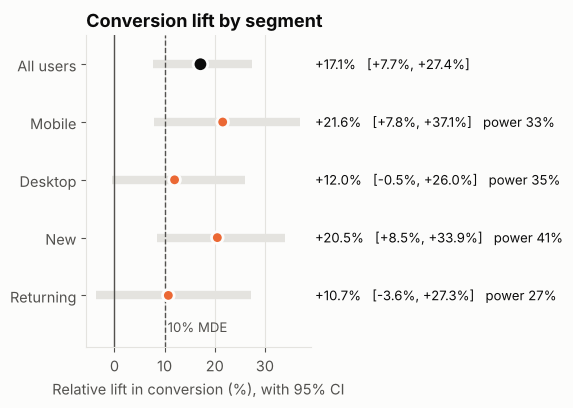

In [30]:
forest = pd.concat([
    pd.DataFrame([{**lift_ci(df, "order_placed"), "segment": "All users"}]).set_index("segment"),
    seg[["lift", "ci_low", "ci_high", "power_at_MDE"]].rename(index=lambda s: s.split(" = ")[1].title()),
])
labels = ["All users", "Mobile", "Desktop", "New", "Returning"]
forest = forest.loc[labels]
y = np.arange(len(forest))[::-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hlines(y, forest["ci_low"] * 100, forest["ci_high"] * 100, color=GRID, linewidth=6)
ax.scatter(forest["lift"] * 100, y, s=[110] + [70] * 4, color=[INK] + [COLORS["treatment"]] * 4,
           zorder=3, edgecolor=SURFACE, linewidth=2)
ax.axvline(0, color=INK_2, linewidth=1)
ax.axvline(MDE_RELATIVE * 100, color=INK_2, linewidth=1, linestyle="--")
ax.text(MDE_RELATIVE * 100 + 0.6, y[-1] - 0.55, "10% MDE", color=INK_2, fontsize=9.5, va="center")
x_max = forest["ci_high"].max() * 100 + 2
for yi, (name, row) in zip(y, forest.iterrows()):
    note = f"{row['lift']:+.1%}   [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]"
    if name != "All users":
        note += f"   power {row['power_at_MDE']:.0%}"
    ax.text(1.02, yi, note, va="center", color=INK, fontsize=9.5, transform=ax.get_yaxis_transform())
ax.set_yticks(y, forest.index)
ax.set_ylim(y[-1] - 0.9, y[0] + 0.5)
ax.set_xlim(min(-5, forest["ci_low"].min() * 100 - 2), x_max)
ax.set_xlabel("Relative lift in conversion (%), with 95% CI")
ax.set_title("Conversion lift by segment")
ax.grid(axis="y", visible=False)
fig.tight_layout(rect=(0, 0, 0.66, 1))
fig.savefig(FIG_DIR / "06_segment_forest.png", dpi=150, bbox_inches="tight", pad_inches=0.25)
plt.show()

### Novelty & segmentation takeaways

**Novelty effect — yes, and it matters.**
- Plan selection: the lift fell from **+32% in week 1 to +18% in week 2**, and the regression confirms a significant decay (p = 0.0002). The price framing's pull is fading as it stops being new.
- Conversion: the same direction (+21% → +12%), but conversion has ~5x fewer events than plan selection, so the decay isn't statistically detectable in this window. Absence of proof of decay is not proof of no decay.
- **The steady-state estimate (week 2) is +12% with a CI that includes 0.** The full-test +17% is inflated by the launch week.

**Segmentation — the effect is consistent; the segments are just small.**
- All four segments point in the same direction (+11% to +22%).
- Desktop and returning users are "not significant" — but every segment is **underpowered** (27–41% power), so those results are inconclusive, not negative.
- The interaction tests find **no evidence that the effect differs** by device (p = 0.37) or user type (p = 0.36). The honest statement is: "the effect looks broadly similar across segments; the data can't distinguish segment differences." Claiming "it only works on mobile" would be a classic over-read.

## 5. Conversion Funnel

The headline lift (+17% conversion) is the *net* of what happened at each stage. Breaking it down by stage shows **where** the treatment helped, where it hurt, and where users are lost. That's what tells a product team what to build next.

Two views:
- **Reach**: out of 1,000 visitors, how many reach each stage, and how many drop off between stages.
- **Step rates**: of the users who reached a stage, what share continued to the next. Each step is tested on its own, with a confidence interval.

In [31]:
stages = ["visit", "plan_selected", "checkout_started", "order_placed"]
stage_labels = ["Visit", "Plan selected", "Checkout started", "Order placed"]
df["visit"] = 1

# Reach per 1,000 visitors
reach = df.groupby("group")[stages].mean().T * 1000
reach.index = stage_labels

# Drop-off between consecutive stages
drop = pd.DataFrame({
    grp: [1 - reach[grp].iloc[i + 1] / reach[grp].iloc[i] for i in range(3)] for grp in ["control", "treatment"]
}, index=[f"{stage_labels[i]} → {stage_labels[i + 1]}" for i in range(3)])

funnel_table = reach.round(1).copy()
funnel_table["treatment − control"] = (reach["treatment"] - reach["control"]).round(1)
print("Users reaching each stage, per 1,000 visitors")
print(funnel_table.to_string(float_format=lambda v: f"{v:,.1f}"), "\n")
print("Drop-off between stages (share of users lost)")
print(drop.map("{:.1%}".format).to_string())

Users reaching each stage, per 1,000 visitors
group             control  treatment  treatment − control
Visit             1,000.0    1,000.0                  0.0
Plan selected       219.5      274.2                 54.8
Checkout started    117.9      140.1                 22.2
Order placed         48.7       57.0                  8.3 

Drop-off between stages (share of users lost)
                                 control treatment
Visit → Plan selected              78.1%     72.6%
Plan selected → Checkout started   46.3%     48.9%
Checkout started → Order placed    58.7%     59.3%


### 5.1 Testing each step separately

Each transition is its own conversion rate, computed only among users who reached the previous stage. Same z-test as Section 3, same log-ratio CI for the relative lift. Three tests → Holm-corrected p-values.

In [32]:
step_rows = []
for i in range(3):
    prev, nxt = stages[i], stages[i + 1]
    sub = df[df[prev] == 1]
    c, t = sub[sub.treatment == 0][nxt], sub[sub.treatment == 1][nxt]
    xc, nc, xt, nt = c.sum(), len(c), t.sum(), len(t)
    _, p = proportions_ztest([xt, xc], [nt, nc])
    lo, hi = confint_proportions_2indep(xt, nt, xc, nc, method="log", compare="ratio", alpha=ALPHA)
    step_rows.append({"step": f"{stage_labels[i]} → {stage_labels[i + 1]}",
                      "control_rate": xc / nc, "treatment_rate": xt / nt,
                      "lift": (xt / nt) / (xc / nc) - 1, "ci_low": lo - 1, "ci_high": hi - 1, "p_value": p})
steps = pd.DataFrame(step_rows).set_index("step")
steps["p_holm"] = multipletests(steps["p_value"], method="holm")[1]
steps["verdict"] = np.select(
    [(steps.p_holm < ALPHA) & (steps.lift > 0), (steps.p_holm < ALPHA) & (steps.lift < 0)],
    ["Treatment better", "Treatment worse"], default="No clear difference")

show = steps.copy()
for c in ["control_rate", "treatment_rate"]:
    show[c] = show[c].map("{:.1%}".format)
for c in ["lift", "ci_low", "ci_high"]:
    show[c] = show[c].map("{:+.1%}".format)
show[["p_value", "p_holm"]] = show[["p_value", "p_holm"]].map("{:.4f}".format)
show

,control_rate,treatment_rate,lift,ci_low,ci_high,p_value,p_holm,verdict
step,,,,,,,,
Visit → Plan selected,21.9%,27.4%,+25.0%,+20.7%,+29.4%,0.0000,0.0000,Treatment better
Plan selected → Checkout started,53.7%,51.1%,-4.9%,-8.5%,-1.2%,0.0095,0.0190,Treatment worse
Checkout started → Order placed,41.3%,40.7%,-1.4%,-7.7%,+5.4%,0.6795,0.6795,No clear difference


### 5.2 Funnel visualization

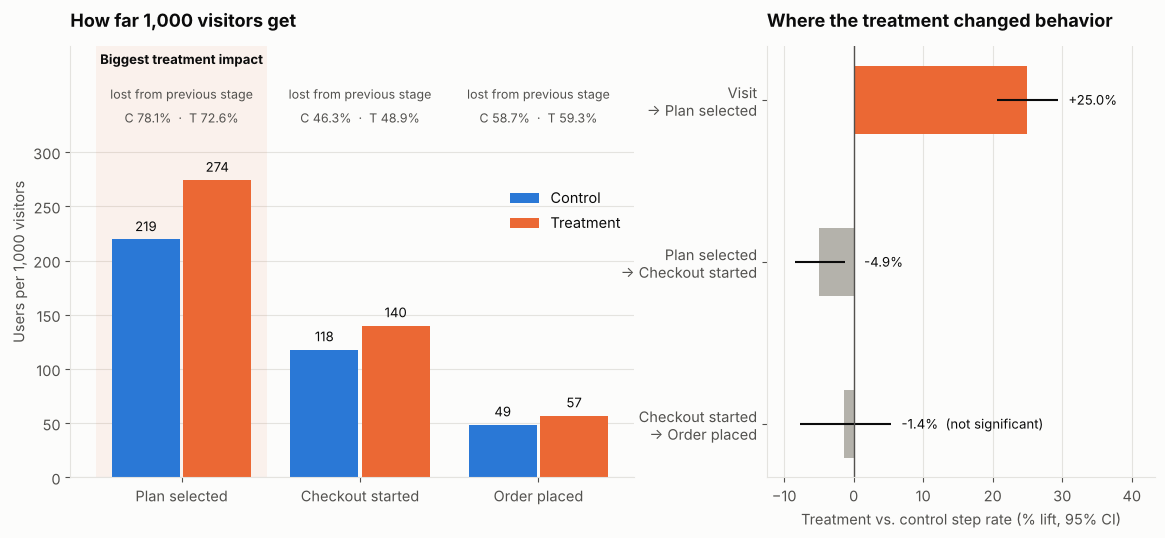

In [33]:
biggest = steps["lift"].abs().idxmax()
biggest_idx = list(steps.index).index(biggest)

fig = plt.figure(figsize=(14, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.45, 1], wspace=0.28)
ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# --- Left: reach per 1,000 visitors (every visitor starts at 1,000) -------
plot_stages = stage_labels[1:]
x = np.arange(len(plot_stages))
w = 0.38
ymax = reach.iloc[1:].to_numpy().max() * 1.45
ax1.axvspan(biggest_idx - 0.48, biggest_idx + 0.48, color=COLORS["treatment"], alpha=0.07, lw=0)
for i, grp in enumerate(["control", "treatment"]):
    vals = reach[grp].iloc[1:].to_numpy()
    xs = x + (i - 0.5) * (w + 0.02)
    ax1.bar(xs, vals, width=w, color=COLORS[grp], label=grp.title())
    for xi, v in zip(xs, vals):
        ax1.text(xi, v + ymax * 0.012, f"{v:,.0f}", ha="center", va="bottom", fontsize=9.5, color=INK)

# Drop-off into each stage, in one fixed row above the bars
for j in range(3):
    ax1.text(j, ymax * 0.86, f"lost from previous stage\nC {drop['control'].iloc[j]:.1%}  ·  T {drop['treatment'].iloc[j]:.1%}",
             ha="center", va="center", fontsize=9, color=INK_2, linespacing=1.5)
ax1.text(biggest_idx, ymax * 0.97, "Biggest treatment impact", ha="center", va="center",
         fontsize=9.5, color=INK, fontweight="bold")

ax1.set_xticks(x, plot_stages)
ax1.set_ylim(0, ymax)
ax1.set_yticks(np.arange(0, reach.iloc[1:].to_numpy().max() * 1.15, 50))
ax1.set_ylabel("Users per 1,000 visitors")
ax1.set_title("How far 1,000 visitors get", pad=14)
ax1.grid(axis="x", visible=False)
ax1.legend(loc="center right", bbox_to_anchor=(1, 0.62))

# --- Right: lift at each step --------------------------------------------
y = np.arange(len(steps))[::-1]
bar_colors = [COLORS["treatment"] if s == biggest else "#b4b2ab" for s in steps.index]
ax2.barh(y, steps["lift"] * 100, color=bar_colors, height=0.42)
ax2.hlines(y, steps["ci_low"] * 100, steps["ci_high"] * 100, color=INK, linewidth=1.5)
ax2.axvline(0, color=INK_2, linewidth=1)
for yi, (name, r) in zip(y, steps.iterrows()):
    sig = "" if r["p_holm"] < ALPHA else "  (not significant)"
    ax2.text(max(r["ci_high"], 0) * 100 + 1.5, yi, f"{r['lift']:+.1%}{sig}", va="center", fontsize=9.5, color=INK)
ax2.set_yticks(y, [s.replace(" → ", "\n→ ") for s in steps.index])
ax2.set_xlim(steps["ci_low"].min() * 100 - 4, steps["ci_high"].max() * 100 + 14)
ax2.set_xlabel("Treatment vs. control step rate (% lift, 95% CI)")
ax2.set_title("Where the treatment changed behavior", pad=14)
ax2.grid(axis="y", visible=False)

fig.savefig(FIG_DIR / "07_conversion_funnel.png", dpi=150, bbox_inches="tight", pad_inches=0.25)
plt.show()

### 5.3 What the checkout leak costs

If the treatment's extra plan selections had converted at the *control* checkout rate, how many more orders would we get? This sizes the opportunity for a follow-up fix.

In [34]:
r_sel_t = steps.loc[steps.index[0], "treatment_rate"]
r_chk_c = steps.loc[steps.index[1], "control_rate"]
r_ord_t = steps.loc[steps.index[2], "treatment_rate"]
counterfactual = r_sel_t * r_chk_c * r_ord_t

print(f"Treatment conversion (actual):                     {p_t:.2%}")
print(f"Treatment conversion if checkout matched control:  {counterfactual:.2%}")
print(f"Orders left on the table:                          {1000 * (counterfactual - p_t):.1f} per 1,000 visitors")
print(f"Share of the top-of-funnel gain lost at checkout:  "
      f"{(counterfactual - p_t) / (counterfactual - p_c):.0%}")

Treatment conversion (actual):                     5.70%
Treatment conversion if checkout matched control:  5.99%
Orders left on the table:                          3.0 per 1,000 visitors
Share of the top-of-funnel gain lost at checkout:  26%


### Funnel takeaways

- **Biggest impact: plan selection.** "$9.99 / serving" moved +25% more visitors to choose a plan. This is where the price framing lives, and it's where the win comes from.
- **The checkout leak is real.** Among plan-selectors, the treatment's checkout rate is significantly *lower*. Users who chose a plan based on a per-serving price meet the weekly total at checkout, and some balk. This is the sticker-shock tradeoff.
- **Order completion is unaffected.** Once at checkout, both groups finish at the same rate.
- **Next experiment:** show the weekly total alongside the per-serving price on the plan page, so there's no surprise at checkout. The calculation above sizes that opportunity.